# Where did the extra runs come from?

**The question, given the season contrasts.** Run rates rose in every phase, clearly in the powerplay (+0.73 runs per over) and directionally in the middle (+0.36) and death (+0.68). A run rate is the sum of several mechanical things: how often the ball goes for four, how often for six, how often nothing is scored, how many runs are run when the ball is not hit to the fence, and extras. Knowing which of those moved says what kind of batting change 2024 was: bigger hits, more hits, fewer dots, or better running.

**What this notebook does.** Runs per legal ball is an exact identity in five rates: fours per ball, sixes per ball, the dot share among non-boundary balls, runs per non-boundary scoring ball (running), and byes plus leg byes per ball. The season change in the run rate is attributed to those five by Shapley values: every ordering of the components is walked, each moved from its 2023 to its 2024 value in turn, and the increments averaged, so the contributions add up to the observed change exactly. A second arrangement of the same identity splits boundaries into *how often* (boundaries per ball) and *how big* (six share among boundaries, a six adding two runs to a four). Both run per phase and for the whole innings, on all innings (the same basis as the phase run-rate contrasts), and everything is rebuilt on each of the shared match resamples so every contribution has an interval.

**How to read this notebook.** *Contribution* is in runs per over, the amount of the run-rate change a component accounts for; *share of change* is that as a fraction of the total. The `run_rate_change` row is the total and reproduces the run-rate contrast in `mean_level_and_tail.ipynb`; `identity_max_abs_error` is the largest gap between the components' sum and the total across resamples and should be at floating-point precision. Wides and no-balls are not legal balls and do not enter, which is the run-rate convention used throughout.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/run_rate_mechanics/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from run_rate_mechanics import run_rate_decomposition as rrd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "run_rate_mechanics"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
PRODUCER = "run_rate_mechanics.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}")
EXTRA = {"n_resamples": N_ITER, "fixture": USING_FIXTURE}

rows=34,967  matches=145


## Decomposition per phase

Per phase and arrangement: each component's rate in both seasons, its contribution in runs per over with interval and P(positive), and its share of the change. First the mechanism arrangement (fours, sixes, dots, running, extras), then boundary frequency against boundary size.

In [3]:
table = rrd.run_all_phases(df, settings, SEED, n_iter=N_ITER)
results_io.write_table(table, settings, ANALYSIS, "run_rate_decomposition", SEED, PRODUCER, EXTRA)
print(table.loc[table["component"] == "run_rate_change", ["phase", "arrangement", "contribution_rpo", "ci_low", "ci_high", "identity_max_abs_error"]].to_string(index=False))
table[table["arrangement"] == "fours_sixes_dots_running_extras"].round(4)

        phase                     arrangement  contribution_rpo    ci_low  ci_high  identity_max_abs_error
    powerplay fours_sixes_dots_running_extras          0.727883  0.168491 1.300324            3.108624e-15
    powerplay     boundary_frequency_and_size          0.727883  0.168491 1.300324            7.119305e-15
       middle fours_sixes_dots_running_extras          0.364194 -0.204988 0.925122            2.442491e-15
       middle     boundary_frequency_and_size          0.364194 -0.204988 0.925122            5.606626e-15
        death fours_sixes_dots_running_extras          0.684948 -0.029227 1.395826            3.552714e-15
        death     boundary_frequency_and_size          0.684948 -0.029227 1.395826            7.438494e-15
whole_innings fours_sixes_dots_running_extras          0.537016  0.079645 0.989719            2.220446e-15
whole_innings     boundary_frequency_and_size          0.537016  0.079645 0.989719            7.216450e-15


,phase,arrangement,component,rate_2023,rate_2024,contribution_rpo,ci_low,ci_high,p_positive,share_of_change,identity_max_abs_error
0,powerplay,fours_sixes_dots_running_extras,fours,0.1799,0.1854,0.1172,-0.1989,0.4455,0.7540,0.1610,NaN
1,powerplay,fours_sixes_dots_running_extras,sixes,0.0457,0.0638,0.5973,0.2350,0.9705,0.9996,0.8206,NaN
2,powerplay,fours_sixes_dots_running_extras,dots,0.5903,0.5842,0.0328,-0.1170,0.1793,0.6698,0.0451,NaN
3,powerplay,fours_sixes_dots_running_extras,running,1.1811,1.1573,-0.0449,-0.1003,0.0099,0.0544,-0.0617,NaN
4,powerplay,fours_sixes_dots_running_extras,extras,0.0266,0.0309,0.0256,-0.0373,0.0924,0.7750,0.0351,NaN
5,powerplay,fours_sixes_dots_running_extras,run_rate_change,8.3719,9.0998,0.7279,0.1685,1.3003,0.9957,1.0000,0.0
12,middle,fours_sixes_dots_running_extras,fours,0.0941,0.0983,0.0827,-0.1479,0.3144,0.7603,0.2271,NaN
13,middle,fours_sixes_dots_running_extras,sixes,0.0607,0.0690,0.2620,-0.1246,0.6435,0.9115,0.7194,NaN
14,middle,fours_sixes_dots_running_extras,dots,0.3683,0.3651,0.0185,-0.1124,0.1529,0.6010,0.0507,NaN
15,middle,fours_sixes_dots_running_extras,running,1.1293,1.1344,0.0162,-0.0392,0.0706,0.7138,0.0445,NaN


It was sixes, and almost nothing else. Of the powerplay's +0.73 runs per over, sixes account for +0.60 (interval +0.24 to +0.97), the only component that clears; fours add +0.12, dots and extras next to nothing, and running slightly less than nothing (−0.04, fewer runs per non-boundary scoring ball). Across the whole innings sixes carry +0.38 of the +0.54, about 72% of the change. The same mechanism runs through the middle (sixes +0.26 of +0.36, P 0.91) and the death (sixes +0.41 and fours +0.25 of +0.68), weaker and less certain outside the powerplay. The dot share moved by less than a point in every phase and running is flat everywhere: the non-boundary game did not change at all. The 2024 acceleration was in the air and over the rope, not in strike rotation.

In [4]:
table[table["arrangement"] == "boundary_frequency_and_size"].round(4)

,phase,arrangement,component,rate_2023,rate_2024,contribution_rpo,ci_low,ci_high,p_positive,share_of_change,identity_max_abs_error
6,powerplay,boundary_frequency_and_size,boundary_frequency,0.2256,0.2492,0.5629,0.0857,1.0631,0.9906,0.7733,NaN
7,powerplay,boundary_frequency_and_size,six_share_of_boundaries,0.2027,0.2559,0.1516,0.0467,0.2576,0.9977,0.2083,NaN
8,powerplay,boundary_frequency_and_size,dots,0.5903,0.5842,0.0328,-0.1170,0.1793,0.6698,0.0451,NaN
9,powerplay,boundary_frequency_and_size,running,1.1811,1.1573,-0.0449,-0.1003,0.0099,0.0544,-0.0617,NaN
10,powerplay,boundary_frequency_and_size,extras,0.0266,0.0309,0.0256,-0.0373,0.0924,0.7750,0.0351,NaN
11,powerplay,boundary_frequency_and_size,run_rate_change,8.3719,9.0998,0.7279,0.1685,1.3003,0.9957,1.0000,0.0
18,middle,boundary_frequency_and_size,boundary_frequency,0.1548,0.1673,0.3057,-0.1726,0.7695,0.9017,0.8393,NaN
19,middle,boundary_frequency_and_size,six_share_of_boundaries,0.3920,0.4122,0.0390,-0.0529,0.1291,0.7957,0.1072,NaN
20,middle,boundary_frequency_and_size,dots,0.3683,0.3651,0.0185,-0.1124,0.1529,0.6010,0.0507,NaN
21,middle,boundary_frequency_and_size,running,1.1293,1.1344,0.0162,-0.0392,0.0706,0.7138,0.0445,NaN


The powerplay found the fence more often, not only harder: boundaries per ball contribute +0.56 (interval +0.09 to +1.06) and the six share among boundaries +0.15 (interval +0.05 to +0.26; sixes went from 20% to 26% of powerplay boundaries). About three quarters of the powerplay rise is more boundaries and a quarter is boundaries turning into sixes. At the death the story is frequency alone: boundaries per ball contribute +0.64 of +0.68 (clears) while the six share sat at 46% in both seasons. In the middle overs frequency again dominates (+0.31 of +0.36) with size adding little.

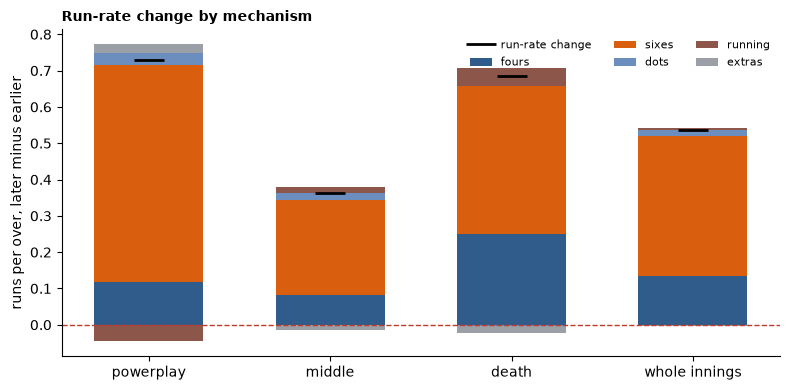

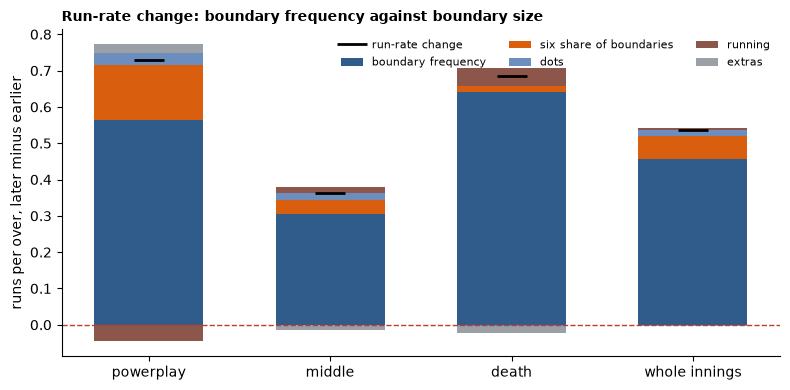

In [5]:
for arrangement, title in (("fours_sixes_dots_running_extras", "Run-rate change by mechanism"),
                           ("boundary_frequency_and_size", "Run-rate change: boundary frequency against boundary size")):
    fig = rrd.plot_contributions(table, arrangement, title)
    results_io.write_figure(fig, settings, ANALYSIS, f"contributions_{arrangement}", SEED, PRODUCER)
    plt.show()

The run-rate rise of 2024 was a boundary rise: more balls reached the fence in every phase, and in the powerplay more of them cleared it. Nothing changed in dots, running or extras. "Teams scored faster" should be read as "teams hit more boundaries, and in the powerplay more sixes", which is the same finding the six-rate contrast, the batter-level decomposition and the shot-level rung each arrived at from a different side.